# Assignment 2 — Final Test Evaluation

**Purpose:** Evaluate frozen models once on the previously inspected chronological benchmark.

This notebook is an executable evidence view over the shared local pipeline. The
command-line runner and notebook call the same stage implementation, preventing code
drift. Completed artifacts are reused; no Google Colab or Google Drive runtime is used.


In [1]:
# Local WSL project bootstrap. Dependency installation belongs to the
# locked project environment and is intentionally not repeated in notebooks.
from pathlib import Path
import json
import os
import platform
import sys

candidate = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [candidate, *candidate.parents] if (path / "shared").exists()),
    candidate,
)
if not (PROJECT_ROOT / "shared").exists():
    raise FileNotFoundError(
        "Open this notebook from the local odl-assignment project root."
    )
os.environ["ODL_PROJECT_ROOT"] = str(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from shared.config import PATHS
from shared.runtime import RuntimeOptions
from shared.workflow import run_stage

OPTIONS = RuntimeOptions.from_environment()
print("Project root:", PROJECT_ROOT)
print("Run mode:", OPTIONS.mode)
print("Device policy:", OPTIONS.device)
print("WSL distribution:", os.getenv("WSL_DISTRO_NAME", "not detected"))


I0000 00:00:1786540932.900560    5714 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1786540932.960823    5714 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Project root: /home/nicholas/code/odl-assignment
Run mode: smoke
Device policy: gpu
WSL distribution: Ubuntu-24.04


I0000 00:00:1786540934.292450    5714 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Run the shared stage or load its verified completed result.
STAGE_SUMMARY = run_stage("evaluate", options=OPTIONS)
STAGE_SUMMARY


{'winner': 'tuned_final',
 'winner_mae': 10.674672387319681,
 'tuned_mae': 10.674672387319681,
 'persistence_mae': 10.844663088849135,
 'improvement_over_persistence_percent': 1.567505602864177,
 'test_anchors': 10062,
 'statistically_superior_to_basic_lstm': True,
 'run_mode': 'smoke'}

In [3]:
# Record the exact runtime used for this output when preflight evidence exists.
environment_path = PATHS.environment_artifacts / f"environment_{OPTIONS.mode}.json"
ENVIRONMENT = (
    json.loads(environment_path.read_text(encoding="utf-8"))
    if environment_path.exists()
    else {"status": "preflight evidence not yet generated"}
)
ENVIRONMENT


{'captured_at_utc': '2026-08-12T13:18:29.136112+00:00',
 'project_root': '/home/nicholas/code/odl-assignment',
 'platform': 'Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39',
 'system': 'Linux',
 'release': '6.6.87.2-microsoft-standard-WSL2',
 'python': '3.12.3',
 'wsl_distribution': 'Ubuntu-24.04',
 'device': 'gpu',
 'tensorflow_gpu_devices': ['/physical_device:GPU:0'],
 'batch_size': 256,
 'mixed_precision': False,
 'nvidia_smi': {'available': True,
  'name': 'NVIDIA GeForce RTX 3050 Laptop GPU',
  'driver_version': '591.74',
  'memory.total': '4096',
  'memory.used': '665',
  'utilization.gpu': '3',
  'temperature.gpu': '57',
  'power.draw': '18.22'},
 'packages': {'tensorflow': '2.21.0',
  'numpy': '2.3.5',
  'pandas': '2.3.3',
  'pyarrow': '25.0.0',
  'scikit-learn': '1.9.0',
  'matplotlib': '3.11.1',
  'seaborn': '0.13.2'},
 'git': {'available': True,
  'revision': '8cbcae3e1948b87b42012417b61d73ab859f470e',
  'dirty': True},
 'experiment_config': {'methodology_versi

## Overall comparison and computational evidence

**Decision.** MAE is primary because it is interpretable in µg/m³ and less dominated by
spikes; RMSE exposes large misses, R² measures explained variation, and sMAPE provides
relative error. Parameter and timing evidence adds efficiency. **Trade-off.** No single
metric captures public-health costs, so all claims use the metric panel and subgroup
evidence. This period is called a frozen benchmark—not untouched—because aggregate
results from the earlier methodology were already inspected.


In [4]:
import pandas as pd
from IPython.display import Image, display

suffix = OPTIONS.artifact_suffix
overall_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"final_overall_metrics{suffix}.csv"
)
inference = pd.read_csv(
    PATHS.assignment2_tables / f"inference_timing{suffix}.csv"
)
display(overall_metrics)
display(inference)


,model,n,mae,rmse,r2,smape_percent
0,tuned_final,10062,10.674672,20.416426,0.946748,21.848731
1,persistence,10062,10.844663,20.653041,0.945506,22.139761
2,basic_cnn,10062,13.888378,23.657747,0.928497,28.817621
3,basic_lstm,10062,24.878776,53.181649,0.638671,32.059517
4,daily_persistence,10062,62.354105,94.628100,-0.143984,83.502328


,model,inference_seconds,parameters
0,basic_lstm,0.397934,29249
1,basic_cnn,0.438147,22913
2,tuned_final,0.453532,95361


## Robustness by station, season, and pollution intensity

Grouped metrics expose where aggregate performance hides difficult conditions. Seed
tables compare every model rather than only the winner.


In [5]:
station_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"final_metrics_by_station{suffix}.csv"
)
season_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"final_metrics_by_season{suffix}.csv"
)
pollution_metrics = pd.read_csv(
    PATHS.assignment2_tables / f"final_metrics_by_pollution_band{suffix}.csv"
)
residual_diagnostics = pd.read_csv(
    PATHS.assignment2_tables / f"residual_diagnostics{suffix}.csv"
)
display(station_metrics)
display(season_metrics)
display(pollution_metrics)
display(residual_diagnostics)


,model,station,n,mae,rmse,r2,smape_percent
0,persistence,Aotizhongxin,5029,11.054683,21.011762,0.950379,21.138972
1,persistence,Changping,5033,10.634810,20.288271,0.938301,23.139755
2,daily_persistence,Aotizhongxin,5029,67.296282,101.296969,-0.153279,84.832648
3,daily_persistence,Changping,5033,57.415855,87.458088,-0.146529,82.173065
4,basic_lstm,Aotizhongxin,5029,27.970447,58.625509,0.613709,33.012802
5,basic_lstm,Changping,5033,21.789563,47.118033,0.667218,31.106990
6,basic_cnn,Aotizhongxin,5029,14.400444,24.567252,0.932165,27.951438
7,basic_cnn,Changping,5033,13.376718,22.712616,0.922675,29.683116
8,tuned_final,Aotizhongxin,5029,10.814783,20.704183,0.951821,20.760891
9,tuned_final,Changping,5033,10.534673,20.124789,0.939292,22.935707


,model,season,n,mae,rmse,r2,smape_percent
0,persistence,autumn,4304,9.563662,16.468442,0.942720,20.966726
1,persistence,summer,1473,6.430414,10.038284,0.897483,23.248531
2,persistence,winter,4285,13.648775,26.354601,0.943934,22.936849
3,daily_persistence,autumn,4304,52.598978,72.050223,-0.096402,78.038512
4,daily_persistence,summer,1473,26.834352,36.864046,-0.382550,66.342955
5,daily_persistence,winter,4285,84.362660,123.876639,-0.238699,94.889029
6,basic_lstm,autumn,4304,18.070246,31.575141,0.789433,28.044248
7,basic_lstm,summer,1473,9.625931,13.469476,0.815424,29.970449
8,basic_lstm,winter,4285,36.960774,74.683224,0.549772,36.810723
9,basic_cnn,autumn,4304,12.864109,18.897490,0.924576,29.728226


,model,pollution_band,n,mae,rmse,r2,smape_percent
0,persistence,low,3064,4.922650,12.378113,-5.919997,36.833512
1,persistence,moderate,4253,9.821303,17.369635,0.503536,19.111477
2,persistence,high,1448,15.785912,25.171017,-0.515415,11.642202
3,persistence,extreme,1297,22.673863,35.362382,0.833251,9.077390
4,daily_persistence,low,3064,57.934399,104.602722,-493.177471,102.604821
5,daily_persistence,moderate,4253,46.821303,67.134870,-6.416565,82.543426
6,daily_persistence,high,1448,68.600829,82.332863,-15.213486,66.910228
7,daily_persistence,extreme,1297,116.754819,145.850540,-1.836585,60.043215
8,basic_lstm,low,3064,6.047467,12.236174,-5.762204,41.398329
9,basic_lstm,moderate,4253,13.886699,19.748394,0.358244,25.957225


,model,mean_residual,median_residual,underprediction_percent,extreme_mean_residual,extreme_underprediction_percent
0,persistence,-0.007255,1.000000,50.457166,5.020817,56.129530
1,daily_persistence,-0.220334,7.000000,56.946929,89.473400,82.960678
2,basic_lstm,14.617674,1.687621,55.545617,112.461838,100.000000
3,basic_cnn,5.029991,4.055187,66.497714,12.734331,64.379337
4,tuned_final,-0.159951,0.249275,51.351620,6.638978,60.524287


## Temporal uncertainty and diagnostic plots

Paired moving-block intervals resample complete calendar days, retaining every station
within a day. One-day intervals are a sensitivity check; seven-day blocks are the
official superiority test because they preserve short-range temporal dependence.
Diagnostic plots reveal bias, extremes, and time-local behaviour.


,comparison,analysis,mean_mae_difference_a_minus_b,ci95_lower,ci95_upper,block_length_days,n_calendar_days,n_rows,bootstrap_samples,seed
0,tuned_final_vs_basic_lstm,sensitivity,-14.204104,-18.359909,-10.942044,1,212,10062,100,42
1,tuned_final_vs_basic_lstm,official,-14.204104,-21.725632,-8.765027,7,212,10062,100,42
2,tuned_final_vs_basic_cnn,sensitivity,-3.213705,-3.712494,-2.701280,1,212,10062,100,42
3,tuned_final_vs_basic_cnn,official,-3.213705,-3.916897,-2.613353,7,212,10062,100,42
4,tuned_final_vs_persistence,sensitivity,-0.169991,-0.211053,-0.128430,1,212,10062,100,42
5,tuned_final_vs_persistence,official,-0.169991,-0.208873,-0.145159,7,212,10062,100,42


{'statistically_superior_to_basic_lstm': True,
 'rule': 'claim superiority only when the paired seven-day moving-block CI is below zero',
 'official_block_length_days': 7,
 'sensitivity_block_length_days': 1,
 'bootstrap_samples': 100,
 'test_description': 'frozen chronological benchmark previously inspected',
 'test_used_for_model_selection': False}

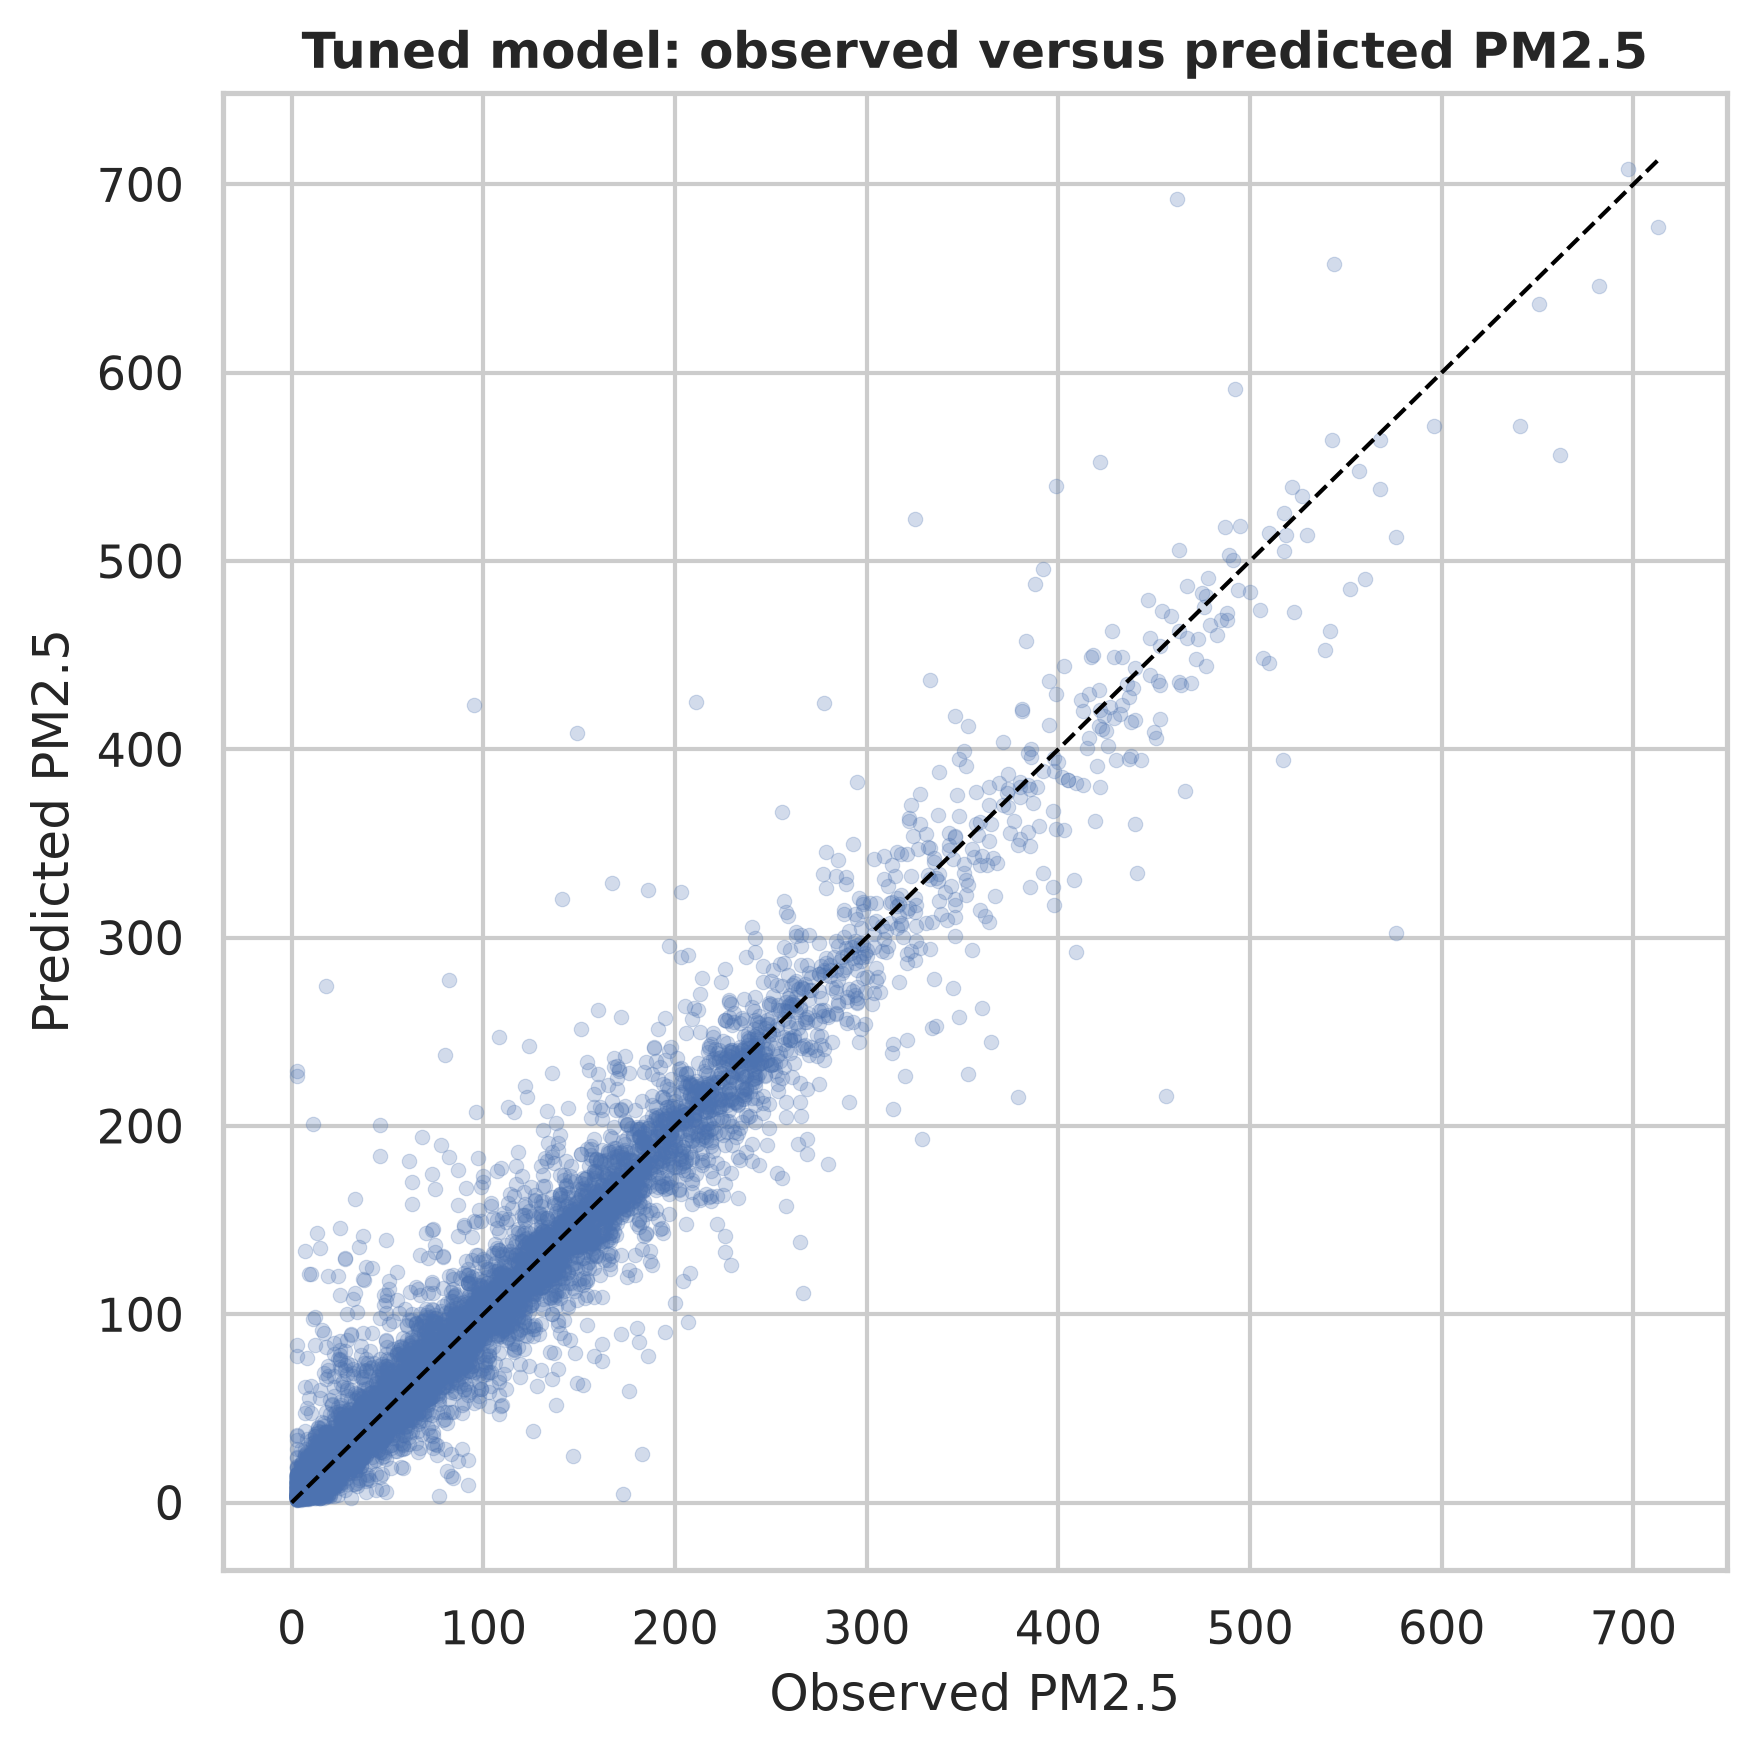

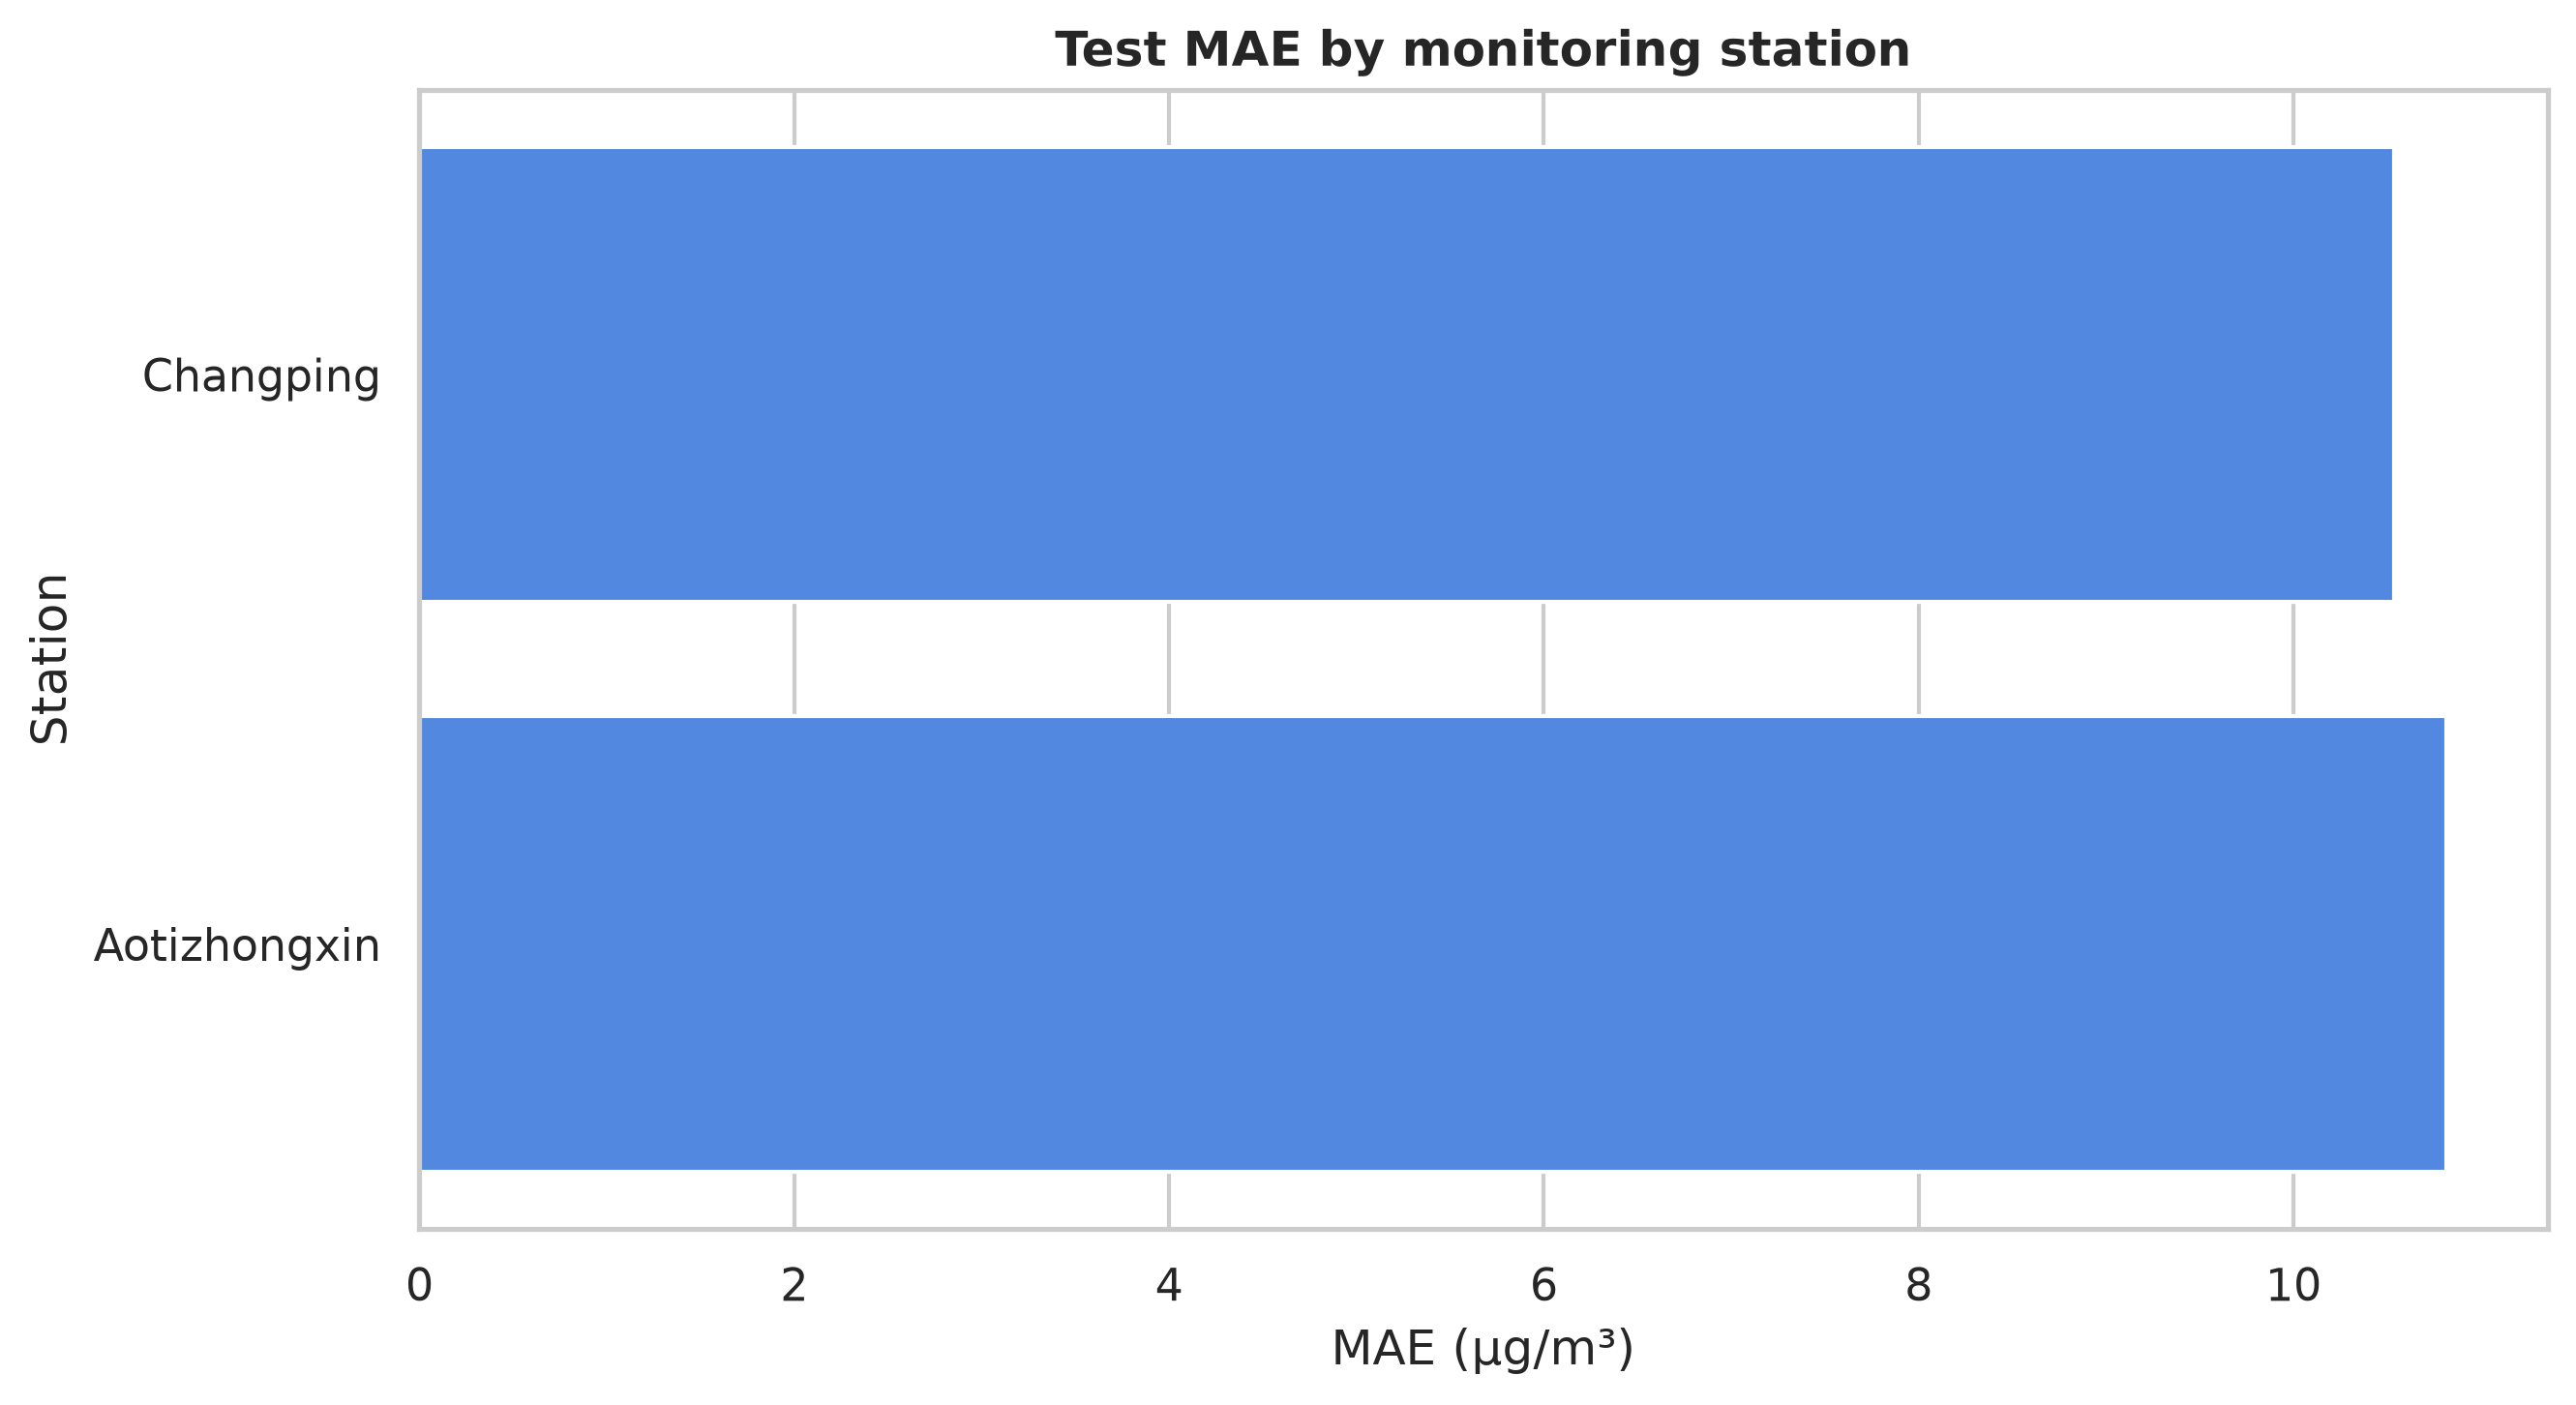

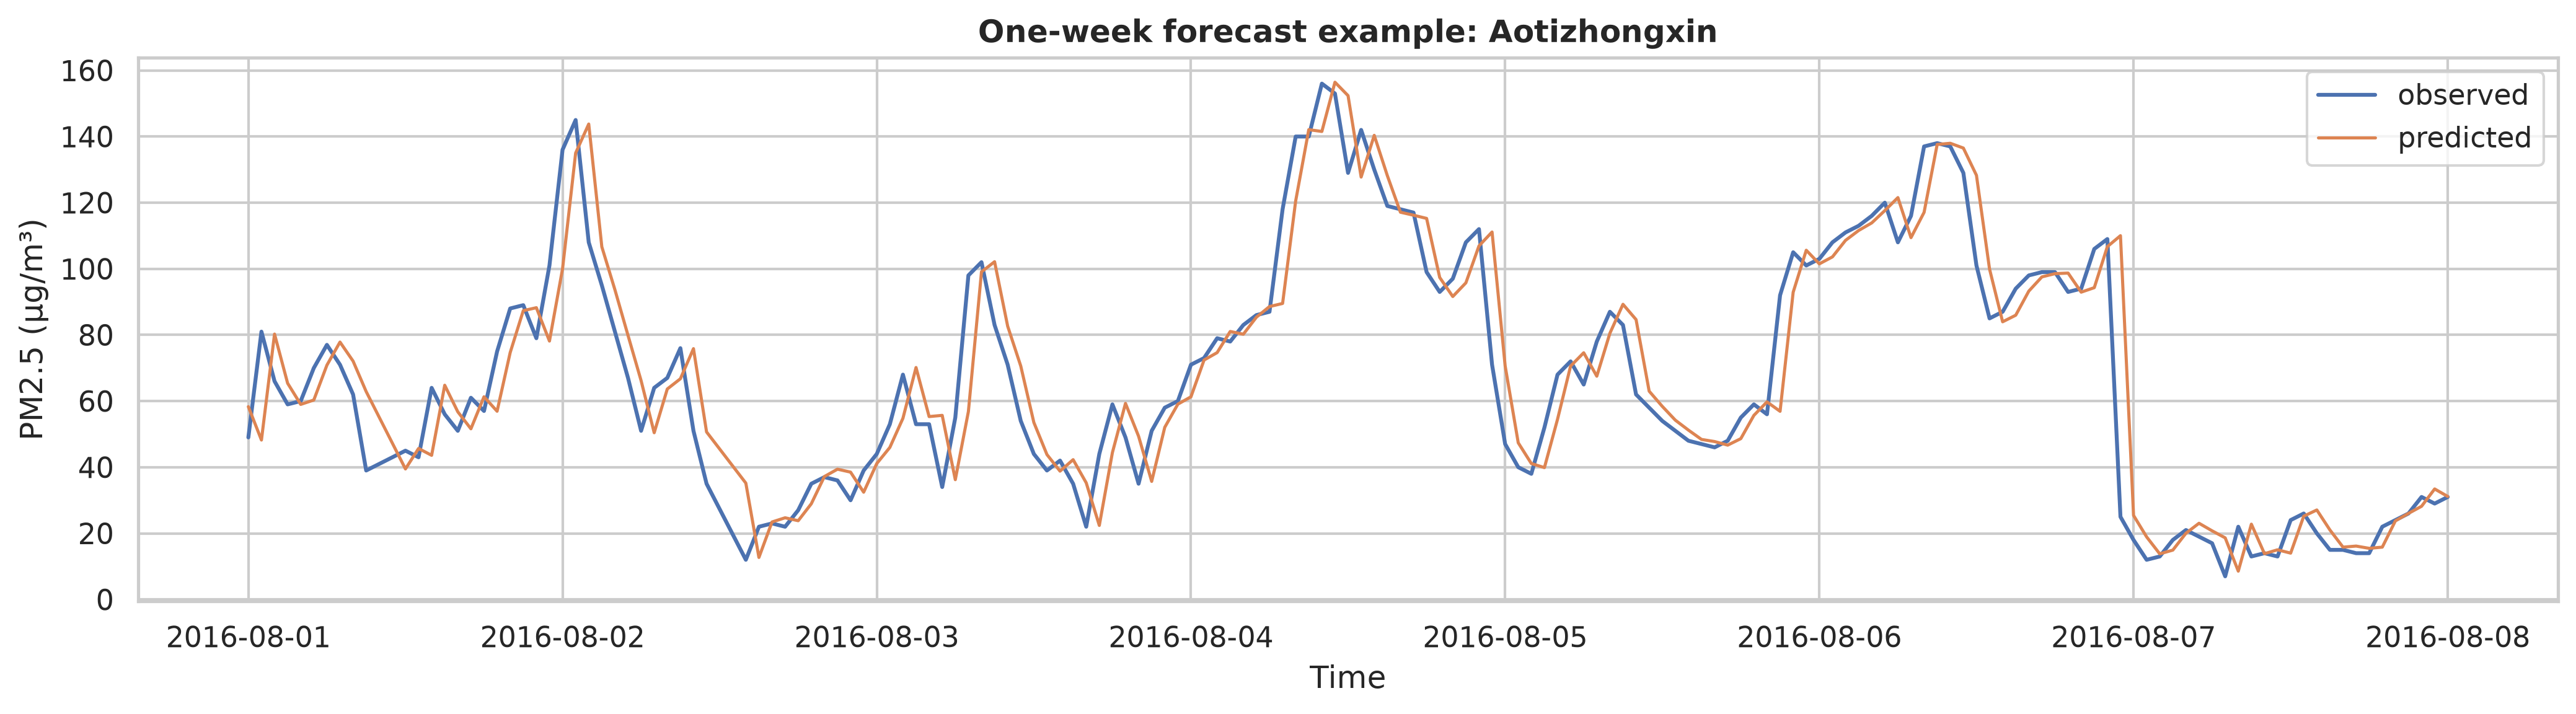

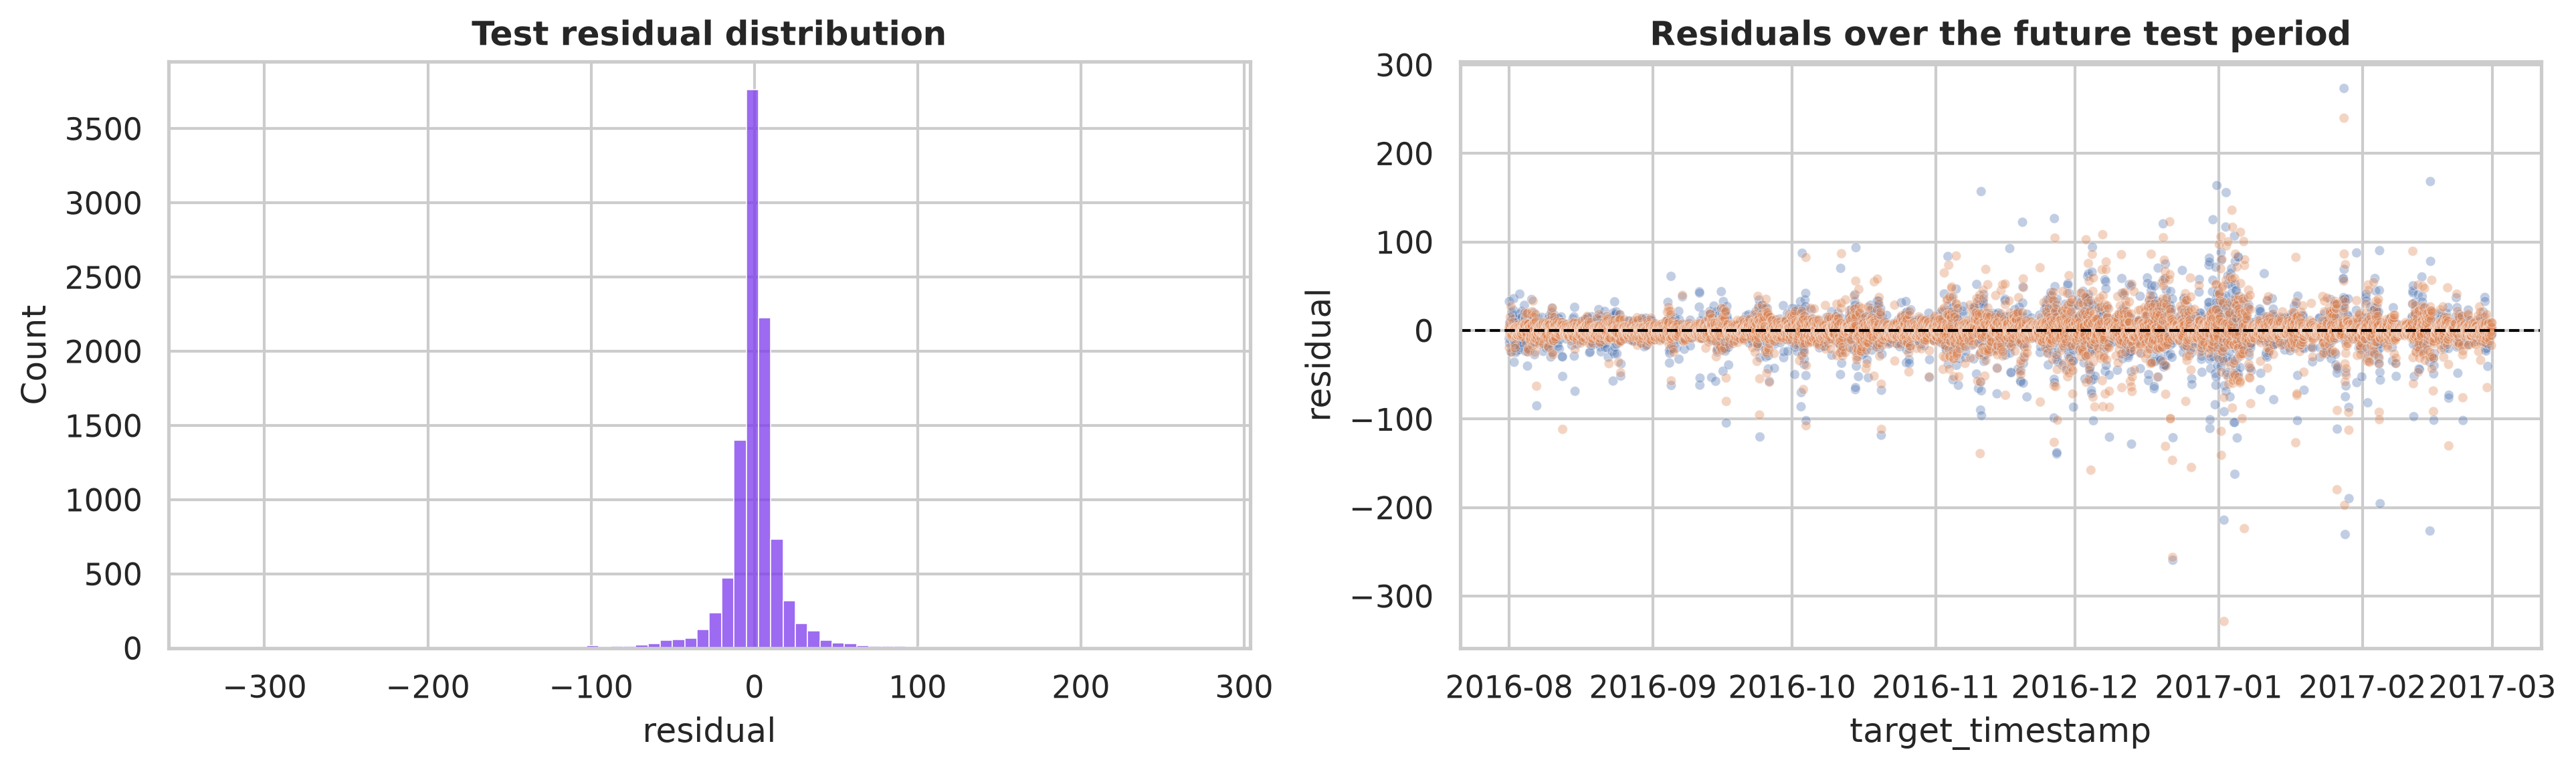

Published metrics are not directly comparable when datasets, horizons, splits, or preprocessing differ. Final benchmark evaluation complete.


In [6]:
bootstrap = pd.read_csv(
    PATHS.assignment2_tables / f"paired_moving_block_bootstrap{suffix}.csv"
)
display(bootstrap)
optimization_claim = json.loads(
    (PATHS.assignment2_tables / f"optimization_claim{suffix}.json").read_text(
        encoding="utf-8"
    )
)
display(optimization_claim)
display(Image(filename=str(
    PATHS.assignment2_figures / f"final_actual_vs_predicted{suffix}.png"
)))
display(Image(filename=str(
    PATHS.assignment2_figures / f"final_station_mae{suffix}.png"
)))
display(Image(filename=str(
    PATHS.assignment2_figures / f"final_example_week{suffix}.png"
)))
display(Image(filename=str(
    PATHS.assignment2_figures / f"final_residual_analysis{suffix}.png"
)))
print(
    "Published metrics are not directly comparable when datasets, horizons, splits, "
    "or preprocessing differ. Final benchmark evaluation complete."
)
